## *DATA ANALYSIS PYTHON PROJECT - BLINKET ANALYSIS* 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df = pd.read_csv("blinkit_data.csv")
df.head()

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2010,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2000,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0


In [3]:
df.tail()

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
8518,low fat,NCT53,Health and Hygiene,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.000000,NaN,164.5526,4.0
8519,low fat,FDN09,Snack Foods,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.034706,NaN,241.6828,4.0
8520,low fat,DRE13,Soft Drinks,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.027571,NaN,86.6198,4.0
8521,reg,FDT50,Dairy,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.107715,NaN,97.8752,4.0
8522,reg,FDM58,Snack Foods,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.000000,NaN,112.2544,4.0


In [4]:
df.shape

(8523, 12)

In [5]:
df.columns

Index(['Item Fat Content', 'Item Identifier', 'Item Type',
       'Outlet Establishment Year', 'Outlet Identifier',
       'Outlet Location Type', 'Outlet Size', 'Outlet Type', 'Item Visibility',
       'Item Weight', 'Sales', 'Rating'],
      dtype='str')

In [6]:
df.dtypes

Item Fat Content                 str
Item Identifier                  str
Item Type                        str
Outlet Establishment Year      int64
Outlet Identifier                str
Outlet Location Type             str
Outlet Size                      str
Outlet Type                      str
Item Visibility              float64
Item Weight                  float64
Sales                        float64
Rating                       float64
dtype: object

In [7]:
df.describe()

,Outlet Establishment Year,Item Visibility,Item Weight,Sales,Rating
count,8523.000000,8523.000000,7060.000000,8523.000000,8523.000000
mean,2010.831867,0.066132,12.857645,140.992782,3.965857
std,8.371760,0.051598,4.643456,62.275067,0.605651
min,1998.000000,0.000000,4.555000,31.290000,1.000000
25%,2000.000000,0.026989,8.773750,93.826500,4.000000
50%,2012.000000,0.053931,12.600000,143.012800,4.000000
75%,2017.000000,0.094585,16.850000,185.643700,4.200000
max,2022.000000,0.328391,21.350000,266.888400,5.000000


# *DATA CLINING*

In [8]:
 df["Item Fat Content"].unique()

<ArrowStringArray>
['Regular', 'Low Fat', 'low fat', 'LF', 'reg']
Length: 5, dtype: str

In [9]:
df["Item Fat Content"] = df["Item Fat Content"].replace({'LF':'Low Fat',
                                                        'low fat':'Low Fat',
                                                        'reg': 'Regular'})

In [10]:
df["Item Fat Content"].unique()

<ArrowStringArray>
['Regular', 'Low Fat']
Length: 2, dtype: str

# *KPI's  REQUIREMENTS*

In [17]:
#Total sum of the sales
total_sales = df['Sales'].sum()

#Average sales
avg_slaes = df['Sales'].mean()

#No of Items sold
No_of_Items_sold = df['Sales'].count()

#Average ratings
avg_ratings = df['Rating'].mean()

print(f"Total Sales: ${total_sales:,.0f}") 
print(f"Average sales: ${avg_slaes:,.2f}") 
print(f"No of Items sold: {No_of_Items_sold:,.0f}") 
print(f"Average ratings: {avg_ratings:,.1f}") 

Total Sales: $1,201,681
Average sales: $140.99
No of Items sold: 8,523
Average ratings: 4.0


# *CHARTS REQUIREMENTS*

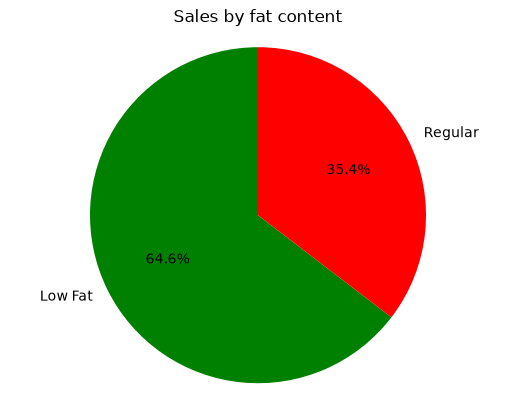

In [23]:
# Total Sales by fat content
Sales_by_fat = df.groupby("Item Fat Content")["Sales"].sum()

plt.pie(Sales_by_fat,labels = Sales_by_fat.index,
                               autopct = '%.1f%%' ,
                               startangle = 90,
                                colors =['green','red'],)

plt.title('Sales by fat content')
plt.axis('equal')
plt.show()

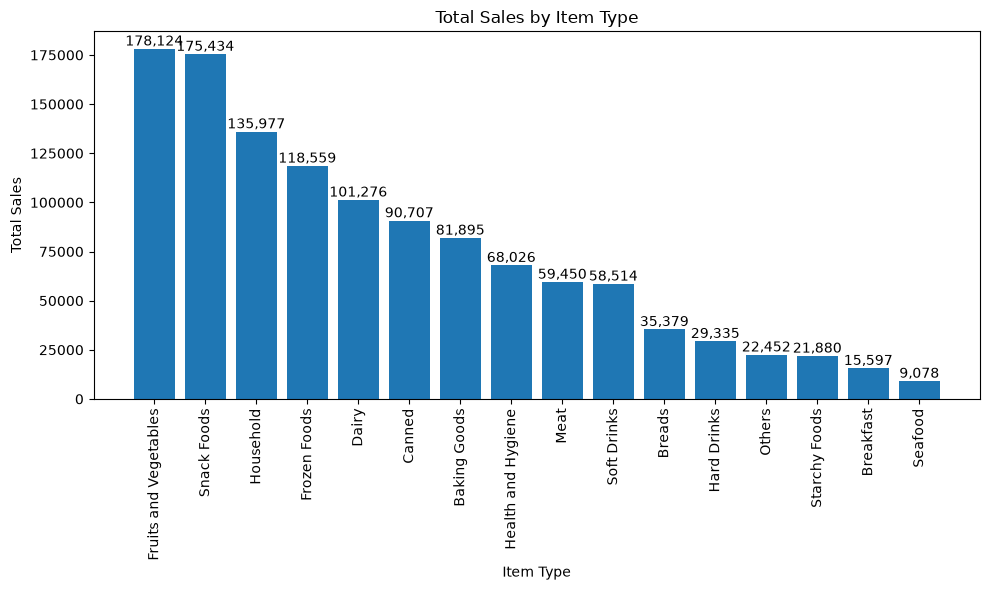

In [25]:
import matplotlib.pyplot as plt

sales_by_type = (
    df.groupby("Item Type")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
bars = plt.bar(sales_by_type.index, sales_by_type.values)

plt.title("Total Sales by Item Type")
plt.xlabel("Item Type")
plt.ylabel("Total Sales")
plt.xticks(rotation=90)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():,.0f}",
        ha="center",
        va="bottom",
    )

plt.tight_layout()
plt.show()

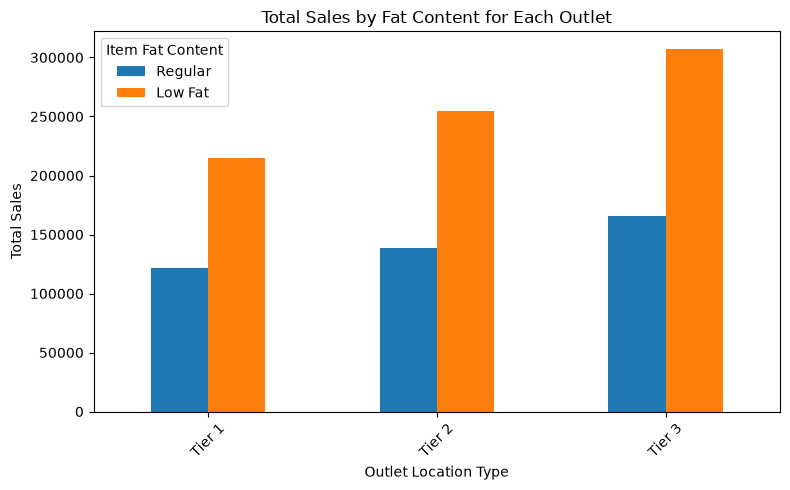

In [27]:
grouped = (
    df.groupby(["Outlet Location Type", "Item Fat Content"])["Sales"]
    .sum()
    .unstack()
)

grouped = grouped[["Regular", "Low Fat"]]

ax = grouped.plot(
    kind="bar",
    figsize=(8, 5),
    title="Total Sales by Fat Content for Each Outlet",
)

ax.set_xlabel("Outlet Location Type")
ax.set_ylabel("Total Sales")
plt.xticks(rotation=45)
ax.legend(title="Item Fat Content")
plt.tight_layout()
plt.show()

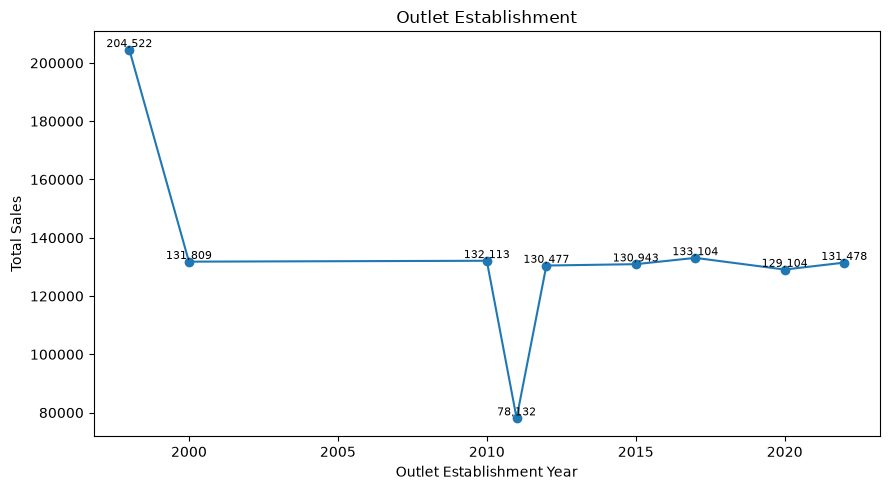

In [28]:
# Total Sales by Outlet Establishment:
sales_by_year = (
    df.groupby("Outlet Establishment Year")["Sales"].sum().sort_index())

plt.figure(figsize=(9, 5))
plt.plot(
    sales_by_year.index,
    sales_by_year.values,
    marker="o",
    linestyle="-",
)

plt.xlabel("Outlet Establishment Year")
plt.ylabel("Total Sales")
plt.title("Outlet Establishment")

for x, y in zip(sales_by_year.index, sales_by_year.values):
    plt.text(x, y, f"{y:,.0f}", ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.show()

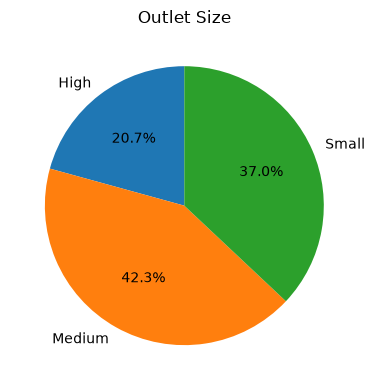

In [29]:
#Sales by Outlet Size
sales_by_size = df.groupby("Outlet Size")["Sales"].sum()

plt.figure(figsize=(4, 4))
plt.pie(
    sales_by_size,
    labels=sales_by_size.index,
    autopct="%1.1f%%",
    startangle=90,
)

plt.title("Outlet Size")
plt.tight_layout()
plt.show()

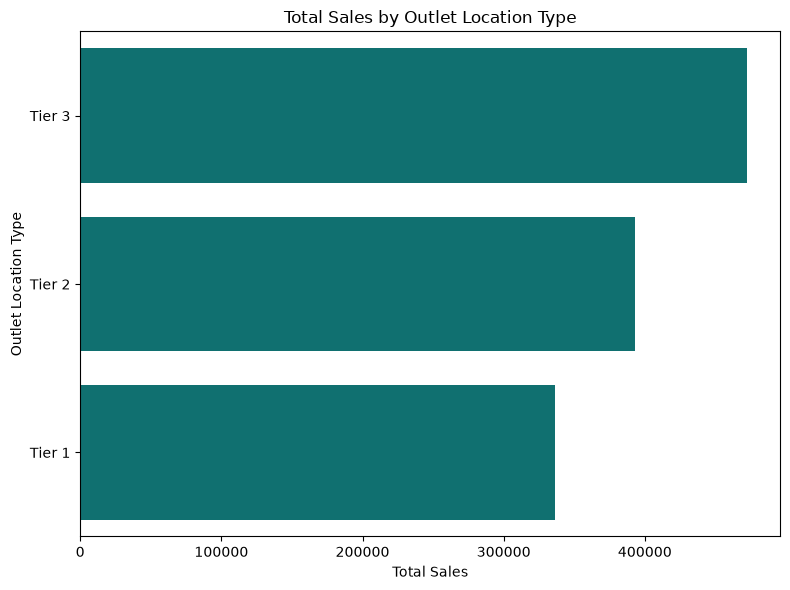

In [32]:
#Sales by Outlet Location
sales_by_location = (
    df.groupby("Outlet Location Type")["Sales"]
    .sum()
    .reset_index()
    .sort_values("Sales", ascending=False)
)

plt.figure(figsize=(8, 6))
ax = sns.barplot(
    x="Sales",
    y="Outlet Location Type",
    data=sales_by_location,
    color='teal'
)

plt.title("Total Sales by Outlet Location Type")
plt.xlabel("Total Sales")
plt.ylabel("Outlet Location Type")

plt.tight_layout()
plt.show()